# Day 3 · 실습 2. DINOv2 Image Embedding과 유사 이미지 검색

**연계 이론:** 이론 3(Self-Supervised Learning과 DINOv2)

사전학습된 DINOv2의 CLS Token에서 Image Embedding을 추출합니다.
Cosine Similarity를 계산하고 Heatmap과 Top-k 검색 결과를 관찰합니다.
DINOv2 모델은 새로 학습하지 않습니다.

**사전 준비:** DINOv2 공개 사전학습 모델을 사용합니다. **별도 계정 승인이나 토큰 입력은 필요하지 않습니다.**
모델: https://huggingface.co/facebook/dinov2-with-registers-small
첫 실행 시 모델 파일을 다운로드하므로 인터넷 연결이 필요합니다.
필요 패키지: torch, torchvision, transformers>=4.56.0, huggingface_hub,
pillow, numpy, pandas, matplotlib. Notebook에 토큰을 직접 입력하지 않습니다.

In [ ]:
import os
import shutil
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from transformers import AutoImageProcessor, AutoModel

# 실행 환경과 모델 설정
SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PROJECT_ROOT = Path(os.getenv("DAY3_PROJECT_ROOT", str(Path.cwd()))).expanduser().resolve()
ASSETS_DIR = PROJECT_ROOT / "assets"
WEIGHTS_DIR = PROJECT_ROOT / "weights"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
DATA_ROOT = Path(os.getenv("DAY3_DATA_ROOT", str(ASSETS_DIR / "hymenoptera_data"))).expanduser().resolve()
# dinov2 모델을 불러옴
MODEL_ID = "facebook/dinov2-with-registers-small"  
for folder in (ASSETS_DIR, WEIGHTS_DIR, OUTPUTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE, "| DINOv2:", MODEL_ID)
print("데이터:", DATA_ROOT)

/Users/jian/Documents/module2_cv_nlp/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1112 22:52:46.081000 32471 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Device: cpu | DINOv2: facebook/dinov2-with-registers-small
데이터: /Users/jian/Documents/module2_cv_nlp/assets/hymenoptera_data


## 1. 개미·벌 데이터셋 준비

실습 02와 같은 경로의 데이터를 재사용합니다.
기존 데이터가 없을 경우 PyTorch 공식 튜토리얼 데이터를 다운로드합니다.

In [2]:
DATA_URL = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"

def ensure_dataset(root=DATA_ROOT):
    required = [root / split / name for split in ("train", "val") for name in ("ants", "bees")]
    if all(p.is_dir() for p in required):
        print("기존 데이터 사용:", root)
        return root

    root.parent.mkdir(parents=True, exist_ok=True)
    archive = root.parent / "hymenoptera_data.zip"
    if not archive.exists():
        print("개미·벌 데이터 다운로드 중...")
        temp = archive.with_suffix(".zip.part")
        try:
            with urllib.request.urlopen(DATA_URL, timeout=90) as response, temp.open("wb") as out:
                shutil.copyfileobj(response, out)
            temp.replace(archive)
        finally:
            temp.unlink(missing_ok=True)

    with zipfile.ZipFile(archive) as zf:
        for member in zf.infolist():
            parts = Path(member.filename).parts
            if not parts or parts[0] != "hymenoptera_data":
                raise ValueError("예상하지 못한 ZIP 경로: " + member.filename)
            if len(parts) == 1:
                continue
            destination = (root / Path(*parts[1:])).resolve()
            if not destination.is_relative_to(root.resolve()):
                raise ValueError("허용되지 않은 ZIP 경로: " + member.filename)
            if member.is_dir():
                destination.mkdir(parents=True, exist_ok=True)
            else:
                destination.parent.mkdir(parents=True, exist_ok=True)
                with zf.open(member) as src, destination.open("wb") as dst:
                    shutil.copyfileobj(src, dst)

    if not all(p.is_dir() for p in required):
        raise FileNotFoundError(f"train/val/ants/bees 폴더를 확인하세요: {root}")
    print("데이터 준비 완료:", root)
    return root

ensure_dataset()

기존 데이터 사용: /Users/jian/Documents/module2_cv_nlp/assets/hymenoptera_data


PosixPath('/Users/jian/Documents/module2_cv_nlp/assets/hymenoptera_data')

## 2. 이미지 12장 선택

검증 이미지에서 개미·벌 각각 6장을 고정된 Random Seed로 선택합니다.
정답 레이블은 출력 해석에만 사용하며 DINOv2에는 전달하지 않습니다.

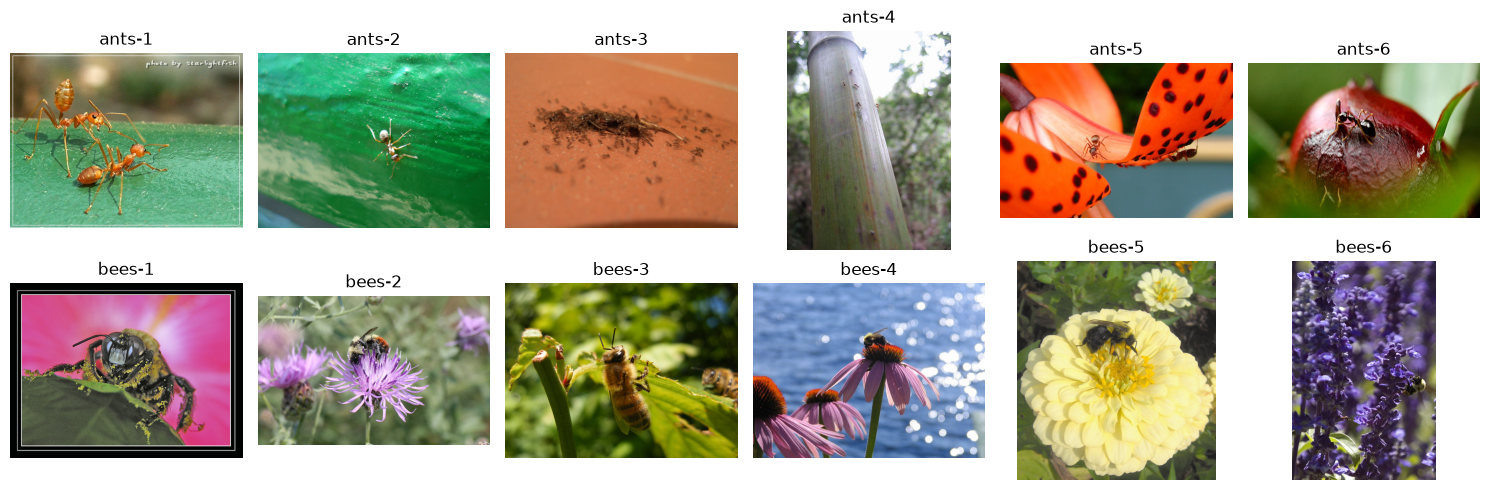

선택 이미지: 12


In [ ]:
# IMAGES_PER_CLASS = 6: 개미 6장, 벌 6장을 선택.
# glob("*.jpg"): 폴더에서 JPG 이미지 파일을 찾기.
# rng.choice(...): 이미지 중 6장을 무작위로 선택.
# replace=False: 같은 이미지를 중복해서 선택하지 않음.

IMAGES_PER_CLASS = 6
image_paths, true_labels = [], []
for class_name in ("ants", "bees"):
    candidates = sorted((DATA_ROOT / "val" / class_name).glob("*.jpg"))
    if len(candidates) < IMAGES_PER_CLASS:
        raise ValueError(f"{class_name}: 이미지가 부족합니다.")
    chosen = rng.choice(len(candidates), size=IMAGES_PER_CLASS, replace=False)
    for idx in chosen:
        image_paths.append(candidates[int(idx)])
        true_labels.append(class_name)

images = []
for path in image_paths:
    with Image.open(path) as im:
        images.append(im.convert("RGB"))
short_labels = [f"{name}-{i+1}" for name in ("ants", "bees")
                for i in range(IMAGES_PER_CLASS)]

fig, axes = plt.subplots(2, IMAGES_PER_CLASS, figsize=(15, 5))
for ax, im, label in zip(axes.flat, images, short_labels):
    ax.imshow(im)
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()
plt.show()
print("선택 이미지:", len(images))

## 3. DINOv2 모델 불러오기

`AutoImageProcessor`는 전처리, `AutoModel`은 사전학습 Backbone을 불러옵니다.
모델은 공개된 `facebook/dinov2-with-registers-small`을 사용합니다.
최초 실행 후에는 `weights/huggingface/` 캐시를 재사용할 수 있습니다.

In [ ]:
try:
    # AutoImageProcessor: DINOv2가 입력받을 수 있도록 이미지를 크기 조정·정규화 등으로 전처리하는 도구
    processor = AutoImageProcessor.from_pretrained(
        MODEL_ID, cache_dir=str(WEIGHTS_DIR / "huggingface")
    )
    # AutoModel: 사전학습된 DINOv2 모델을 불러옴. 여기서는 이미지 분류기 대신 특징을 추출하는 모델 자체를 사용
    model = AutoModel.from_pretrained(
        MODEL_ID, cache_dir=str(WEIGHTS_DIR / "huggingface")
    ).to(DEVICE).eval() ## 모델 추론
except Exception as exc:
    raise RuntimeError(
        "DINOv2 모델 로딩 실패: 인터넷 연결, "
        "모델 경로와 transformers 버전을 확인하세요."
    ) from exc
print("Model:", model.__class__.__name__)
print("Patch size:", model.config.patch_size)
print("Hidden size:", model.config.hidden_size)
print("Register tokens:", model.config.num_register_tokens)

Loading weights: 100%|██████████| 224/224 [00:00<00:00, 13220.26it/s]

Model: Dinov2WithRegistersModel
Patch size: 14
Hidden size: 384
Register tokens: 4


## 4. Token Shape와 Global Image Embedding

DINOv2의 출력은 CLS Token, Register Token, Patch Token을 포함합니다.
이미지 전체의 유사도 비교에는 CLS Token 하나를 사용합니다.

In [ ]:
# 이미지를 모델에 입력하고 특징 추출
INFERENCE_BATCH_SIZE = 4
all_cls_vectors = []
for start in range(0, len(images), INFERENCE_BATCH_SIZE):
    batch = images[start:start + INFERENCE_BATCH_SIZE]
    # 이미지를 DINOv2 모델에 입력할 수 있는 Tensor로 변환
    inputs = processor(images=batch, return_tensors="pt")
    # 입력 Tensor를 모델과 동일한 장치(CPU 또는 GPU)로 이동
    inputs = {name: value.to(DEVICE) for name, value in inputs.items()}
    # 모델의 가중치를 학습하지 않고 특징 추출만 수행
    with torch.inference_mode():
        # 이미지를 DINOv2에 입력하고, Transformer Encoder의 최종 Token 특징 추출
        hidden = model(**inputs).last_hidden_state

    if start == 0:
        _, _, height, width = inputs["pixel_values"].shape
        patch_size = model.config.patch_size
        patch_h, patch_w = patch_size if isinstance(patch_size, (tuple, list)) else (patch_size, patch_size)
        num_patch = (height // patch_h) * (width // patch_w)
        num_register = model.config.num_register_tokens
        expected_tokens = 1 + num_register + num_patch

        # CLS·Register·Patch Token 구분
        cls_tokens = hidden[:, :1, :]
        register_tokens = hidden[:, 1:1 + num_register, :]
        patch_tokens = hidden[:, 1 + num_register:, :]
        assert hidden.shape[1] == expected_tokens
        assert patch_tokens.shape[1] == num_patch

        print("입력 Shape:", tuple(inputs["pixel_values"].shape))
        print("전체 Token:", tuple(hidden.shape))
        print("CLS Token:", tuple(cls_tokens.shape))
        print("Register Tokens:", tuple(register_tokens.shape))
        print("Patch Tokens:", tuple(patch_tokens.shape))

    # 이미지 전체의 Embedding 추출
    all_cls_vectors.append(hidden[:, 0, :].detach().float().cpu())

embeddings = torch.cat(all_cls_vectors, dim=0)
normalized = F.normalize(embeddings, p=2, dim=1)
print("Global Embeddings:", tuple(embeddings.shape))
print("정규화 후 첫 벡터 크기:", round(normalized[0].norm().item(), 6))

입력 Shape: (4, 3, 224, 224)
전체 Token: (4, 261, 384)
CLS Token: (4, 1, 384)
Register Tokens: (4, 4, 384)
Patch Tokens: (4, 256, 384)
Global Embeddings: (12, 384)
정규화 후 첫 벡터 크기: 1.0


## 5. Cosine Similarity와 Heatmap

L2 정규화한 벡터의 내적은 Cosine Similarity와 같습니다.
행렬 대각선은 같은 이미지를 비교한 결과이므로 약 1입니다.

        ants-1  ants-2  ants-3  ants-4  ants-5  ants-6  bees-1  bees-2  bees-3  bees-4  bees-5  bees-6
ants-1   1.000   0.498   0.209   0.125   0.106   0.379  -0.027  -0.036   0.138   0.028   0.010   0.054
ants-2   0.498   1.000   0.298   0.310   0.194   0.598   0.168  -0.055   0.187   0.019   0.036   0.030
ants-3   0.209   0.298   1.000   0.315   0.086   0.313   0.100  -0.032   0.168   0.077  -0.023   0.089
ants-4   0.125   0.310   0.315   1.000   0.245   0.263   0.106  -0.075   0.201   0.070  -0.061   0.087
ants-5   0.106   0.194   0.086   0.245   1.000   0.249   0.281   0.056   0.129   0.122  -0.002  -0.062
ants-6   0.379   0.598   0.313   0.263   0.249   1.000   0.143  -0.007   0.354   0.110  -0.028  -0.055
bees-1  -0.027   0.168   0.100   0.106   0.281   0.143   1.000   0.066   0.288  -0.024   0.112  -0.040
bees-2  -0.036  -0.055  -0.032  -0.075   0.056  -0.007   0.066   1.000   0.088   0.119   0.094   0.079
bees-3   0.138   0.187   0.168   0.201   0.129   0.354   0.288   0.088   

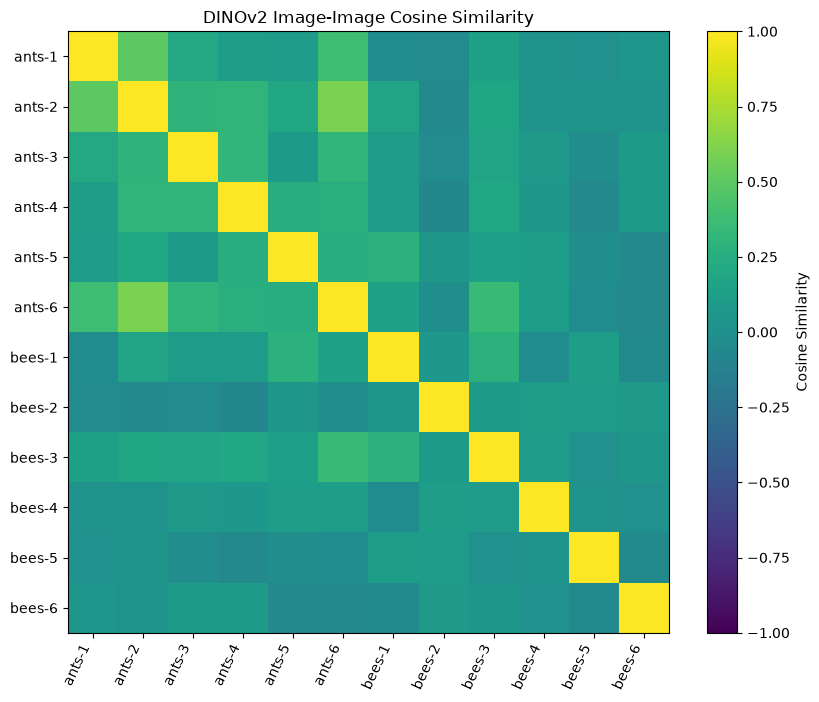

In [6]:
similarity = (normalized @ normalized.T).numpy()
assert similarity.shape == (len(images), len(images))
assert np.allclose(np.diag(similarity), 1.0, atol=1e-5)
similarity_df = pd.DataFrame(similarity, index=short_labels, columns=short_labels)
print(similarity_df.round(3).to_string())

fig, ax = plt.subplots(figsize=(8.5, 7))
heatmap = ax.imshow(similarity, vmin=-1, vmax=1, cmap="viridis")
ax.set_xticks(range(len(short_labels)), short_labels, rotation=65, ha="right")
ax.set_yticks(range(len(short_labels)), short_labels)
ax.set_title("DINOv2 Image-Image Cosine Similarity")
fig.colorbar(heatmap, ax=ax, label="Cosine Similarity")
plt.tight_layout()
plt.show()

## 6. Top-k 유사 이미지 검색

`QUERY_INDEX`는 기준 이미지, `TOP_K`는 검색할 이미지 수입니다.
기준 이미지 자기 자신은 검색 결과에서 제외합니다.

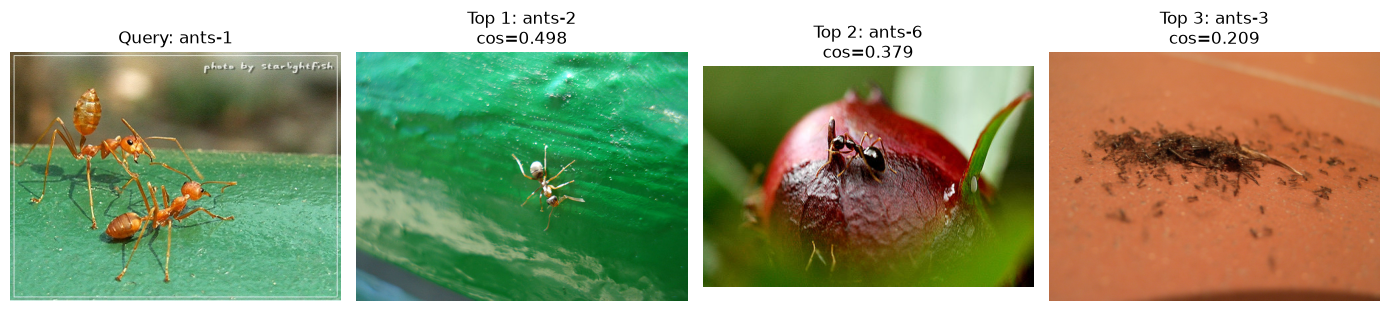

1위: ants-2 | cos=0.4977 | 실제 클래스=ants
2위: ants-6 | cos=0.3794 | 실제 클래스=ants
3위: ants-3 | cos=0.2089 | 실제 클래스=ants


In [7]:
QUERY_INDEX = 0  # 0 ~ 11 사이에서 변경 가능
TOP_K = 3
if not 0 <= QUERY_INDEX < len(images):
    raise ValueError("QUERY_INDEX 범위를 확인하세요.")
if not 1 <= TOP_K < len(images):
    raise ValueError("TOP_K는 1 이상, 전체 이미지 수 미만이어야 합니다.")

query_scores = similarity[QUERY_INDEX].copy()
query_scores[QUERY_INDEX] = -np.inf
ranked = np.argsort(query_scores)[::-1][:TOP_K]

fig, axes = plt.subplots(1, TOP_K + 1, figsize=(3.5 * (TOP_K + 1), 3.5))
axes[0].imshow(images[QUERY_INDEX])
axes[0].set_title(f"Query: {short_labels[QUERY_INDEX]}")
axes[0].axis("off")
for rank, (idx, ax) in enumerate(zip(ranked, axes[1:]), start=1):
    ax.imshow(images[idx])
    ax.set_title(f"Top {rank}: {short_labels[idx]}\ncos={similarity[QUERY_INDEX, idx]:.3f}")
    ax.axis("off")
plt.tight_layout()
plt.show()
for rank, idx in enumerate(ranked, start=1):
    print(f"{rank}위: {short_labels[idx]} | cos={similarity[QUERY_INDEX, idx]:.4f} | "
          f"실제 클래스={true_labels[idx]}")

## 7. 결과 저장 및 요약

- Image Embedding과 유사도 행렬을 저장합니다.
- CLS Token에서 추출한 Embedding으로 이미지 유사도를 계산했습니다.
- 이번 실습에서는 DINOv2의 가중치를 학습하지 않았습니다.
- 이 실습에서는 이미지와 이미지 사이의 유사도를 비교하며, 학습한 가중치를 변경하지 않습니다.

In [8]:
np.save(OUTPUTS_DIR / "day3_02_dinov2_cls_embeddings.npy", embeddings.numpy())
similarity_df.to_csv(OUTPUTS_DIR / "day3_02_dinov2_similarity.csv", encoding="utf-8-sig")
print("결과 저장:", OUTPUTS_DIR)

결과 저장: /Users/jian/Documents/module2_cv_nlp/outputs
